## EDA

In [33]:
import pandas as pd

path = "../DATA/PROCESSED/arxiv_abstracts_sample.csv.gz"
df = pd.read_csv(path, dtype={"id": str})

print(df.shape)
df.head()

(60000, 16)


,id,title,abstract,authors,author_count,categories,primary_category,category_count,field,comments,journal_ref,doi,license,first_version_date,version_count,label
0,2303.00306,A massive interacting galaxy 510 million years...,JWST observations confirm the existence of gal...,"Kristan Boyett, Michele Trenti, Nicha Leethoch...",27,astro-ph.GA,astro-ph.GA,1,astrophysics,"52 pages, 10 figures This version of the artic...",NaN,NaN,http://arxiv.org/licenses/nonexclusive-distrib...,2023-03-01,2,post_chatgpt
1,2303.00410,JWST/NIRSpec Measurements of the Relationships...,We analyze the rest-optical emission-line rati...,"Alice E. Shapley, Naveen A. Reddy, Ryan L. San...",5,astro-ph.GA,astro-ph.GA,1,astrophysics,"10 pages, 4 figures, ApJL, in press",NaN,10.3847/2041-8213/acd939,http://arxiv.org/licenses/nonexclusive-distrib...,2023-03-01,2,post_chatgpt
2,2303.00489,The miniJPAS survey quasar selection II: Machi...,Astrophysical surveys rely heavily on the clas...,"Nat\'alia V.N. Rodrigues, L. Raul Abramo, Caro...",26,astro-ph.GA astro-ph.CO,astro-ph.GA,2,astrophysics,"16 pages, 15 figures, published by MNRAS",Monthly Notices of the Royal Astronomical Soci...,10.1093/mnras/stac2836,http://arxiv.org/licenses/nonexclusive-distrib...,2023-03-01,1,post_chatgpt
3,2303.00584,A Search for Chemical Anomalies of Seven A-typ...,We present a chemical abundance analysis of se...,Yahya Nasolo and \c{S}eyma \c{C}al{\i}\c{s}kan,2,astro-ph.SR,astro-ph.SR,1,astrophysics,NaN,NaN,10.1093/mnras/stad662,http://creativecommons.org/licenses/by/4.0/,2023-03-01,1,post_chatgpt
4,2303.00603,Radio jet precession in M81*,We report four novel position angle measuremen...,"S.D. von Fellenberg, M. Janssen, J. Davelaar, ...",8,astro-ph.HE astro-ph.GA,astro-ph.HE,2,astrophysics,NaN,"A&A 672, L5 (2023)",10.1051/0004-6361/202245506,http://creativecommons.org/licenses/by/4.0/,2023-03-01,1,post_chatgpt


In [34]:
#data types
print(df.dtypes)

id                    object
title                 object
abstract              object
authors               object
author_count           int64
categories            object
primary_category      object
category_count         int64
field                 object
comments              object
journal_ref           object
doi                   object
license               object
first_version_date    object
version_count          int64
label                 object
dtype: object


In [35]:
#number of unique values per column
df.nunique()

id                    60000
title                 59998
abstract              59999
authors               58288
author_count            252
categories             3745
primary_category         37
category_count            9
field                     3
comments              32099
journal_ref            9665
doi                   17640
license                   6
first_version_date     2768
version_count            20
label                     2
dtype: int64

In [36]:
#duplicate papers
df.duplicated(subset=["id"]).sum()

np.int64(0)

In [37]:
# papers per field and period
df.groupby(["field", "label"]).size()

field                      label       
astrophysics               post_chatgpt    10000
                           pre_chatgpt     10000
computational_linguistics  post_chatgpt    10000
                           pre_chatgpt     10000
math                       post_chatgpt    10000
                           pre_chatgpt     10000
dtype: int64

In [38]:
#missing values per column
print(df.isnull().sum())

id                        0
title                     0
abstract                  0
authors                   0
author_count              0
categories                0
primary_category          0
category_count            0
field                     0
comments              16305
journal_ref           50175
doi                   42357
license                   0
first_version_date        0
version_count             0
label                     0
dtype: int64


In [39]:
# percent missing per column
(df.isnull().sum() / len(df) * 100).round(1)

id                     0.0
title                  0.0
abstract               0.0
authors                0.0
author_count           0.0
categories             0.0
primary_category       0.0
category_count         0.0
field                  0.0
comments              27.2
journal_ref           83.6
doi                   70.6
license                0.0
first_version_date     0.0
version_count          0.0
label                  0.0
dtype: float64

Summary:
- 60000 rows, 16 columns. One row is one arXiv paper.
- three fields (math, astrophysics, computational linguistics), 10000 papers per field per period. pre_chatgpt is 2019-01-01 to 2022-11-29, post_chatgpt is 2023-03-01 on. The gap in between was dropped.
- 3 numeric (author_count, category_count, version_count), 13 text. first_version_date is text and needs converting to a date.
- no duplicate ids. One abstract appears twice under two ids, drop before modeling.
- missing: only in comments (27.2%), journal_ref (83.6%), and doi (70.6%). Expected, since many papers have no comments or aren't published in a journal yet. None of the three are used in the model.
- next: convert dates, add year and abstract length, then charts.

In [40]:
# convert date, add year and abstract word count
df["first_version_date"] = pd.to_datetime(df["first_version_date"])
df["year"] = df["first_version_date"].dt.year
df["word_count"] = df["abstract"].str.split().str.len()

df[["year", "word_count"]].describe()

,year,word_count
count,60000.000000,60000.000000
mean,2022.617033,162.226483
std,2.343572,64.991799
min,2019.000000,7.000000
25%,2021.000000,115.000000
50%,2022.500000,161.000000
75%,2025.000000,211.000000
max,2026.000000,672.000000


In [41]:
#setup 
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

colors = {"pre_chatgpt": "skyblue", "post_chatgpt": "violet"}
order = ["pre_chatgpt", "post_chatgpt"]

# dates and year
df["first_version_date"] = pd.to_datetime(df["first_version_date"])
df["year"] = df["first_version_date"].dt.year

# abstract length
df["word_count"] = df["abstract"].str.split().str.len()

# lexical diversity: unique words in the first 50 words
def lexical_diversity(text, n=50):
    words = re.findall(r"[a-z]+", text.lower())[:n]
    return len(set(words)) / n if len(words) == n else np.nan

df["lexical_diversity"] = df["abstract"].apply(lexical_diversity)

# word complexity: average letters per word
def avg_word_length(text):
    words = re.findall(r"[a-z]+", text.lower())
    return np.mean([len(w) for w in words]) if words else np.nan

df["avg_word_length"] = df["abstract"].apply(avg_word_length)

# mentions AI terms
ai_terms = r"\b(?:language model|LLM|GPT|ChatGPT|generative AI|artificial intelligence|machine learning|deep learning|neural network|Claude|Gemini|Copilot)"
df["mentions_ai"] = df["abstract"].str.contains(ai_terms, case=False, regex=True)

# 1. How many papers do we have before and after ChatGPT?

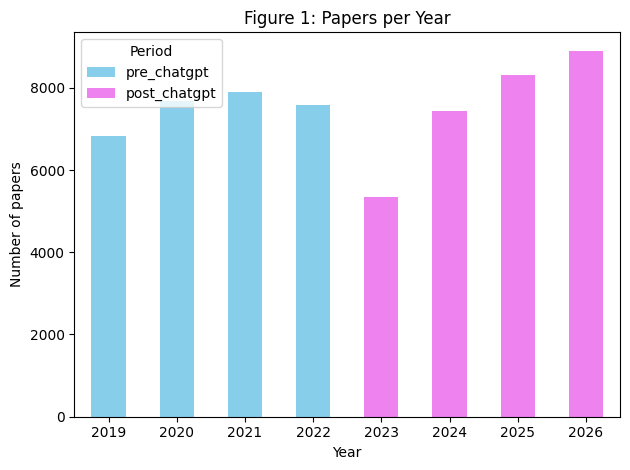

In [42]:
counts = df.groupby(["year", "label"]).size().unstack()[order]
counts.plot(kind="bar", stacked=True, rot=0, color=colors)
plt.title("Figure 1: Papers per Year")
plt.xlabel("Year")
plt.ylabel("Number of papers")
plt.legend(title="Period")
plt.tight_layout()
plt.show()

# 2. Did abstracts get longer after Chat?

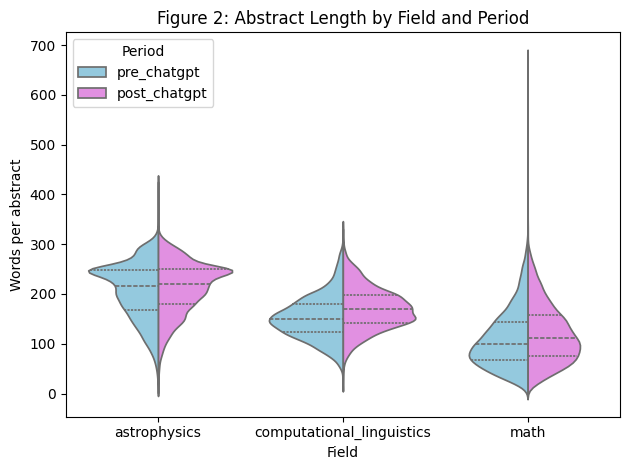

label,pre_chatgpt,post_chatgpt
field,,
astrophysics,216.0,221.0
computational_linguistics,150.0,169.0
math,100.0,111.0


In [48]:
sns.violinplot(data=df, x="field", y="word_count", hue="label", hue_order=order,
               palette=colors, split=True, inner="quart")
plt.title("Figure 2: Abstract Length by Field and Period")
plt.xlabel("Field")
plt.ylabel("Words per abstract")
plt.legend(title="Period")
plt.tight_layout()
plt.show()

df.groupby(["field", "label"])["word_count"].median().unstack()[order]

# 3. Did abstracts use less words after Chat?

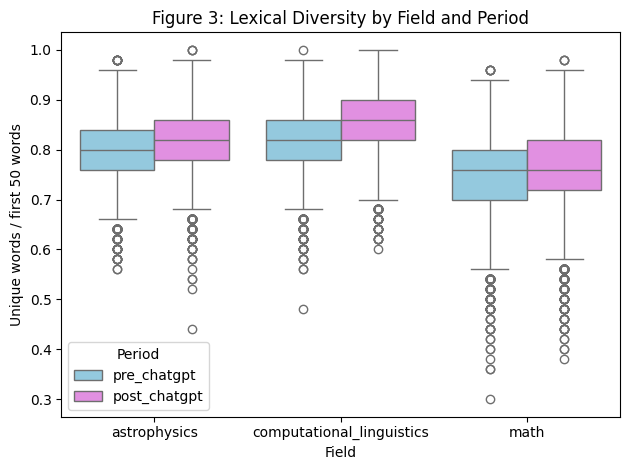

label,pre_chatgpt,post_chatgpt
field,,
astrophysics,0.80,0.82
computational_linguistics,0.82,0.86
math,0.76,0.76


In [44]:
sns.boxplot(data=df, x="field", y="lexical_diversity", hue="label", hue_order=order, palette=colors)
plt.title("Figure 3: Lexical Diversity by Field and Period")
plt.xlabel("Field")
plt.ylabel("Unique words / first 50 words")
plt.legend(title="Period")
plt.tight_layout()
plt.show()

df.groupby(["field", "label"])["lexical_diversity"].median().unstack()[order].round(3)

# 4. Were abstracts using simpler words after AI?

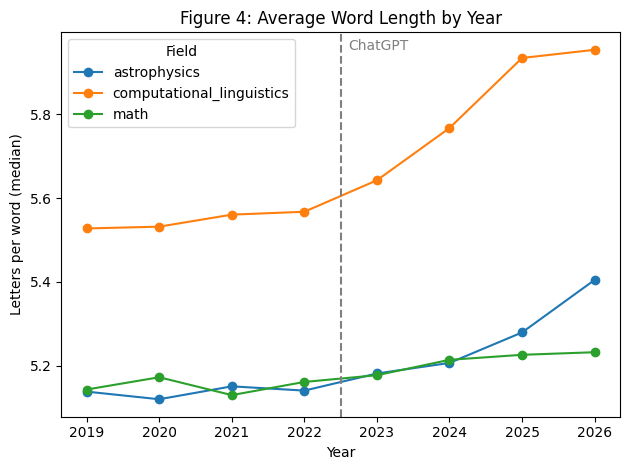

field,astrophysics,computational_linguistics,math
year,,,
2019,5.14,5.53,5.14
2020,5.12,5.53,5.17
2021,5.15,5.56,5.13
2022,5.14,5.57,5.16
2023,5.18,5.64,5.18
2024,5.21,5.77,5.21
2025,5.28,5.93,5.23
2026,5.40,5.95,5.23


In [46]:
yearly = df.groupby(["year", "field"])["avg_word_length"].median().unstack()

yearly.plot(marker="o")
plt.axvline(2022.5, color="gray", linestyle="--")
plt.text(2022.6, yearly.max().max(), "ChatGPT", color="gray")
plt.title("Figure 4: Average Word Length by Year")
plt.xlabel("Year")
plt.ylabel("Letters per word (median)")
plt.legend(title="Field")
plt.tight_layout()
plt.show()

yearly.round(2)

# 5. Could the change be because more papers are about AI now?

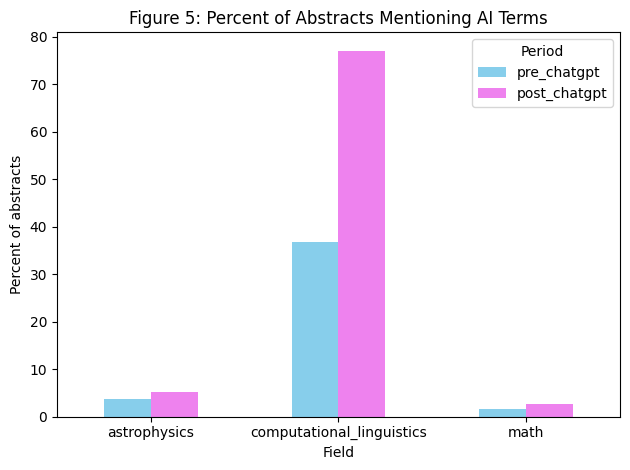

label,pre_chatgpt,post_chatgpt
field,,
astrophysics,3.6,5.1
computational_linguistics,36.8,77.0
math,1.6,2.6


In [47]:
ai_share = (df.groupby(["field", "label"])["mentions_ai"].mean() * 100).unstack()[order]
ai_share.plot(kind="bar", rot=0, color=colors)
plt.title("Figure 5: Percent of Abstracts Mentioning AI Terms")
plt.xlabel("Field")
plt.ylabel("Percent of abstracts")
plt.legend(title="Period")
plt.tight_layout()
plt.show()

ai_share.round(1)

# 6. In the fields where the topics stayed the same, did lexical diversity shift?

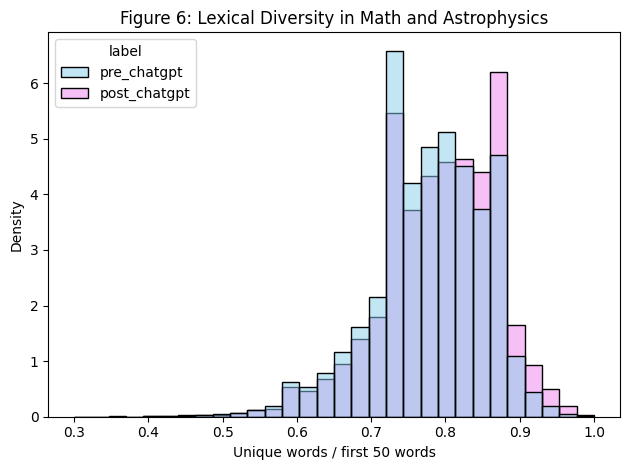

label
pre_chatgpt     0.78
post_chatgpt    0.80
Name: lexical_diversity, dtype: float64

In [49]:
non_ai = df[df["field"].isin(["math", "astrophysics"])]

sns.histplot(data=non_ai, x="lexical_diversity", hue="label", hue_order=order,
             palette=colors, stat="density", common_norm=False, bins=30, alpha=0.5)
plt.title("Figure 6: Lexical Diversity in Math and Astrophysics")
plt.xlabel("Unique words / first 50 words")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

non_ai.groupby("label")["lexical_diversity"].median()[order].round(3)

# 7. Do abstracts with longer words use more varied vocabulary as well?

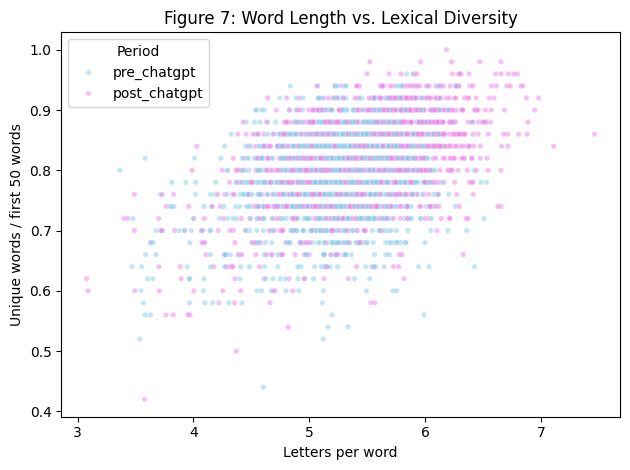

,avg_word_length,lexical_diversity
avg_word_length,1.00,0.48
lexical_diversity,0.48,1.00


In [50]:
sample = df.dropna(subset=["lexical_diversity"]).sample(3000, random_state=549)

sns.scatterplot(data=sample, x="avg_word_length", y="lexical_diversity",
                hue="label", hue_order=order, palette=colors, alpha=0.5, s=15)
plt.title("Figure 7: Word Length vs. Lexical Diversity")
plt.xlabel("Letters per word")
plt.ylabel("Unique words / first 50 words")
plt.legend(title="Period")
plt.tight_layout()
plt.show()

df[["avg_word_length", "lexical_diversity"]].corr().round(2)

Summary:
- Vocabulary didn't get less varied. It stayed flat in math and went up a little in astrophysics (0.80 to 0.82) and computational linguistics (0.82 to 0.86).
- Words got longer after ChatGPT, most in computational linguistics (5.57 to 5.95) and astrophysics (5.14 to 5.40). Math barely changed.
- AI terms jumped in computational linguistics (36.8% to 77.0%) but stayed low in math and astrophysics.
- Writing changed, but it got more complex, not simpler.